# Campus Bus Arrival Time Estimator

## Project Synopsis
- **Problem Statement:** Students may wait unnecessarily because they do not know the approximate arrival time of a campus bus.
- **Methodology:** Use **route distance**, **time of day**, **traffic category**, and **previous travel time** to train and evaluate regression models that estimate bus arrival time.
- **Expected Outcome:** A transparent, beginner-friendly prediction system for approximate campus bus arrival times.

### Dataset Schema
| Column | Role | Description |
|---|---|---|
| `trip_id` | Metadata | Unique identifier for each campus bus trip |
| `route_name` | Context | Campus shuttle corridor name |
| `route_distance_km` | Feature (Numerical) | Remaining distance between bus and student's stop (km) |
| `time_of_day` | Feature (Temporal) | 24-hour clock timestamp (`HH:MM`) |
| `traffic_category` | Feature (Ordinal) | Congestion level (`Low`, `Medium`, `High`) |
| `previous_travel_time_min` | Feature (Numerical) | Duration of the immediately preceding bus trip (minutes) |
| `arrival_time_min` | **Target (Continuous)** | Observed bus arrival duration (minutes) |

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split

from src.config import MODEL_INPUT_COLUMNS, RAW_DATA_PATH, TARGET_COLUMN, TRAFFIC_CATEGORIES
from src.features import (
    build_preprocessor,
    clean_raw_dataset,
    get_transformed_feature_names,
    parse_time_to_hours,
)
from src.generate_data import generate_campus_bus_dataset
from src.train_model import (
    bootstrap_confidence_intervals,
    build_candidate_models,
    compute_regression_metrics,
    evaluate_slice_performance,
    extract_feature_importance,
)

sns.set_theme(style="whitegrid")

if not RAW_DATA_PATH.exists():
    generate_campus_bus_dataset(output_path=RAW_DATA_PATH)

raw_df = pd.read_csv(RAW_DATA_PATH)
print(f"Raw dataset shape: {raw_df.shape}")
display(raw_df.head(6))
display(raw_df.describe(include="all").T)

Raw dataset shape: (1200, 7)


,trip_id,route_name,route_distance_km,time_of_day,traffic_category,previous_travel_time_min,arrival_time_min
0,TRIP-0001,Route A: Main Gate -> North Hostels,3.23,13:18,High,16.70,14.26
1,TRIP-0002,Route B: Central Library -> Academic Block Loop,2.48,18:18,Medium,10.20,9.58
2,TRIP-0003,Route C: Railway Station -> Engineering Quad,5.19,20:52,Low,14.77,14.66
3,TRIP-0004,Route D: South Dorms -> Sports Complex,2.66,15:06,Low,8.78,8.19
4,TRIP-0005,Route A: Main Gate -> North Hostels,3.18,12:00,High,13.76,13.80
5,TRIP-0006,Route B: Central Library -> Academic Block Loop,1.08,13:44,Low,5.80,6.04


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
trip_id,1200,1200,TRIP-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
route_name,1200,4,Route A: Main Gate -> North Hostels,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
route_distance_km,1200.0,NaN,NaN,NaN,3.4924,2.081948,-1.5,1.94,2.94,4.6,9.3
time_of_day,1200,676,09:38,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
traffic_category,1190,3,Low,571,NaN,NaN,NaN,NaN,NaN,NaN,NaN
previous_travel_time_min,1182.0,NaN,NaN,NaN,11.983206,6.250486,-4.0,7.49,10.465,15.415,37.59
arrival_time_min,1194.0,NaN,NaN,NaN,12.362337,6.363588,2.34,7.6325,10.86,15.99,39.35


### Schema & Initial Data Inspection Findings
- The raw log contains **1,200 rows** across 7 columns (2 identifiers/context fields, 4 predictive features matching the project methodology, and 1 continuous target `arrival_time_min`).
- Look closely at the summary table (`min` and `count`): we can already spot anomalies—negative `route_distance_km` / `previous_travel_time_min` values and slightly fewer than 1,200 non-null counts in `previous_travel_time_min`, `traffic_category`, and `arrival_time_min`.
- Next, we quantify every missing and nonsensical entry before deciding how to clean them.

In [2]:
missing_summary = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(2),
})
print("Missing / NULL Frequency in Raw Data:")
display(missing_summary)

bad_distance = raw_df[pd.to_numeric(raw_df["route_distance_km"], errors="coerce") < 0.2]
bad_time = raw_df[raw_df["time_of_day"].apply(parse_time_to_hours).isna()]
bad_prev = raw_df[pd.to_numeric(raw_df["previous_travel_time_min"], errors="coerce") < 1.0]
missing_target = raw_df[raw_df[TARGET_COLUMN].isna()]

print("Corrupted or targetless sample rows:")
display(pd.concat([bad_distance, bad_time, bad_prev, missing_target]).drop_duplicates())

cleaned_df, quality_report = clean_raw_dataset(raw_df)
print(f"Rows before cleaning: {quality_report.total_rows}")
print(f"Rows after removing corrupted/targetless rows: {quality_report.cleaned_rows}")
print("Retained missing feature counts (for train-only imputation):", quality_report.missing_feature_counts)

Missing / NULL Frequency in Raw Data:


,missing_count,missing_pct
trip_id,0,0.00
route_name,0,0.00
route_distance_km,0,0.00
time_of_day,0,0.00
traffic_category,10,0.83
previous_travel_time_min,18,1.50
arrival_time_min,6,0.50


Corrupted or targetless sample rows:


,trip_id,route_name,route_distance_km,time_of_day,traffic_category,previous_travel_time_min,arrival_time_min
232,TRIP-0233,Route A: Main Gate -> North Hostels,-1.50,18:10,High,10.46,12.53
1197,TRIP-1198,Route B: Central Library -> Academic Block Loop,-1.50,08:26,Low,9.13,8.36
130,TRIP-0131,Route C: Railway Station -> Engineering Quad,4.55,25:99,Low,12.58,12.95
1027,TRIP-1028,Route D: South Dorms -> Sports Complex,1.91,25:99,Low,7.51,8.37
83,TRIP-0084,Route D: South Dorms -> Sports Complex,4.95,09:34,High,-4.00,21.76
209,TRIP-0210,Route B: Central Library -> Academic Block Loop,2.36,09:38,High,-4.00,10.88
34,TRIP-0035,Route C: Railway Station -> Engineering Quad,4.66,14:29,Low,11.44,NaN
123,TRIP-0124,Route D: South Dorms -> Sports Complex,3.43,18:48,Low,8.83,NaN
147,TRIP-0148,Route D: South Dorms -> Sports Complex,3.10,13:11,High,13.66,NaN
218,TRIP-0219,Route C: Railway Station -> Engineering Quad,4.96,18:52,Medium,16.01,NaN


Rows before cleaning: 1200
Rows after removing corrupted/targetless rows: 1188
Retained missing feature counts (for train-only imputation): {'route_distance_km': 0, 'time_of_day': 0, 'traffic_category': 10, 'previous_travel_time_min': 18, 'arrival_time_min': 0}


### Data Cleaning & Missing Value Strategy
- **Targetless & Corrupted Rows Dropped:** Rows missing `arrival_time_min` (6 rows) cannot supervise regression training, and rows with physically impossible sensor entries—negative `route_distance_km` (2 rows), invalid timestamps like `25:99` (2 rows), and negative `previous_travel_time_min` (2 rows)—represent logging errors rather than real bus trips. Dropping those **12 unusable rows** leaves **1,188 valid trips**.
- **Imputable Feature Gaps Preserved:** Missing values in `previous_travel_time_min` (18 trips, e.g., first shuttle of the morning when no prior trip exists) and `traffic_category` (10 trips due to feed dropout) remain as `NaN` in `cleaned_df`. Instead of dropping 28 valid trips or imputing across the whole table, we will impute them **strictly inside the training pipeline** (median for numeric features, most frequent for ordinal traffic) after splitting.

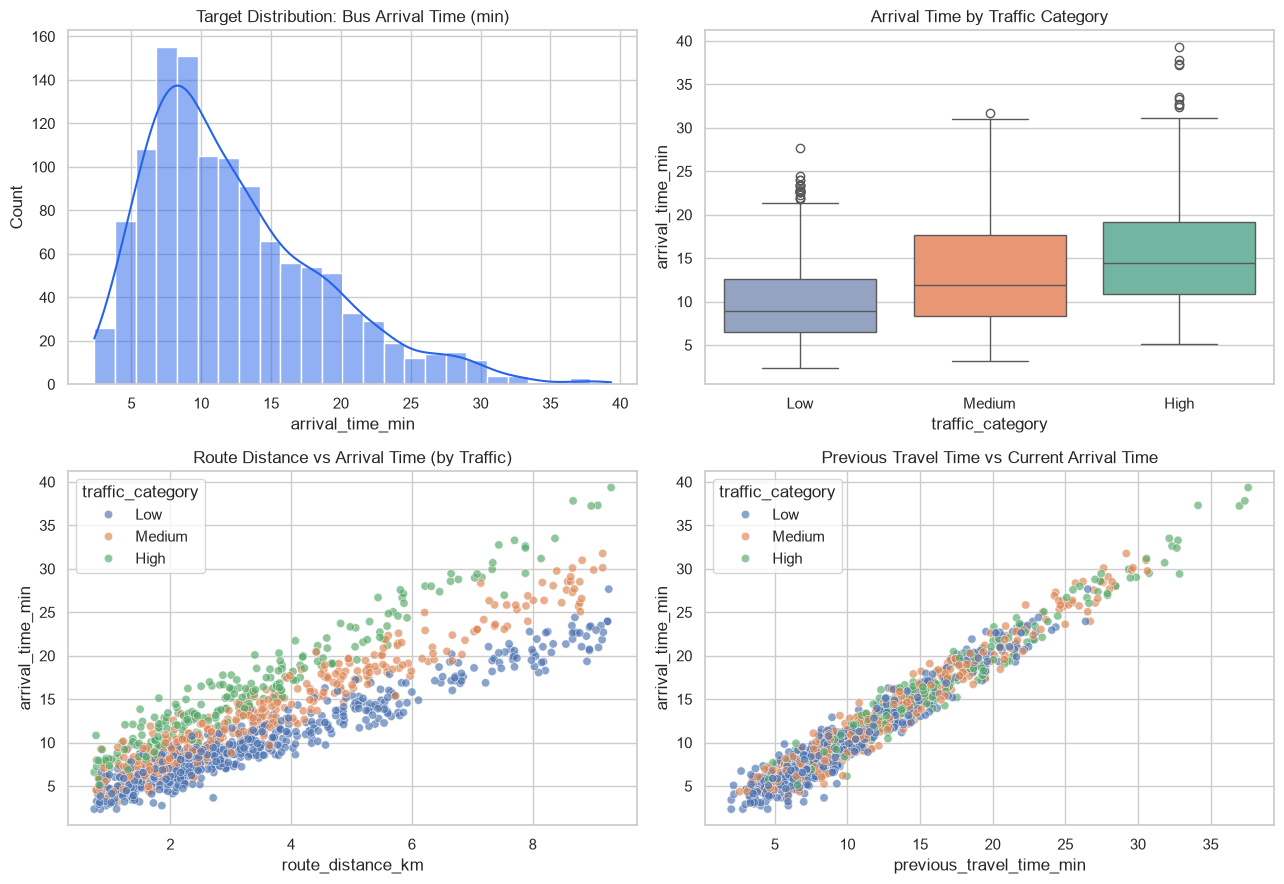

Numeric Correlations with arrival_time_min:


,arrival_time_min
arrival_time_min,1.000000
previous_travel_time_min,0.977909
route_distance_km,0.878341
hour_decimal,-0.099835


In [3]:
eda_df = cleaned_df.copy()
eda_df["hour_decimal"] = eda_df["time_of_day"].apply(parse_time_to_hours)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Target distribution
sns.histplot(eda_df[TARGET_COLUMN], bins=25, kde=True, ax=axes[0, 0], color="#2563eb")
axes[0, 0].set_title("Target Distribution: Bus Arrival Time (min)")
axes[0, 0].set_xlabel("arrival_time_min")

# 2. Target boxplot across traffic categories
sns.boxplot(
    data=eda_df,
    x="traffic_category",
    y=TARGET_COLUMN,
    order=TRAFFIC_CATEGORIES,
    hue="traffic_category",
    palette="Set2",
    legend=False,
    ax=axes[0, 1],
)
axes[0, 1].set_title("Arrival Time by Traffic Category")

# 3. Distance vs Arrival Time
sns.scatterplot(
    data=eda_df,
    x="route_distance_km",
    y=TARGET_COLUMN,
    hue="traffic_category",
    hue_order=TRAFFIC_CATEGORIES,
    alpha=0.65,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Route Distance vs Arrival Time (by Traffic)")

# 4. Time of Day vs Residual/Arrival Pattern
sns.scatterplot(
    data=eda_df,
    x="previous_travel_time_min",
    y=TARGET_COLUMN,
    hue="traffic_category",
    hue_order=TRAFFIC_CATEGORIES,
    alpha=0.65,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Previous Travel Time vs Current Arrival Time")

plt.tight_layout()
plt.show()

print("Numeric Correlations with arrival_time_min:")
display(
    eda_df[["route_distance_km", "previous_travel_time_min", "hour_decimal", TARGET_COLUMN]]
    .corr()[[TARGET_COLUMN]]
    .sort_values(TARGET_COLUMN, ascending=False)
)

### Exploratory Data Analysis Takeaways
- **Target Distribution:** `arrival_time_min` spans roughly 2.3 to 39.4 minutes (mean ~12.4 min) with a mild right tail caused by long cross-campus routes during heavy congestion.
- **Traffic Ordering:** Median arrival times step steadily upward from **Low** -> **Medium** -> **High** traffic, and the steeper slope in the *Distance vs Arrival Time* plot shows an interaction effect (high traffic slows each kilometer further).
- **Momentum Signal:** `previous_travel_time_min` correlates very strongly with `arrival_time_min`, confirming that the most recent shuttle run captures real-time road conditions beyond distance alone.

In [4]:
X = cleaned_df[MODEL_INPUT_COLUMNS].copy()
y = cleaned_df[TARGET_COLUMN].copy()

# Split BEFORE any imputation, encoding, or scaling (70% Train / 15% Val / 15% Test)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=(0.15 / 0.85), random_state=42
)

print(f"Train rows: {len(X_train)} | Val rows: {len(X_val)} | Test rows: {len(X_test)}")
print(
    f"Mean target (min) -> Train: {y_train.mean():.2f}, "
    f"Val: {y_val.mean():.2f}, Test: {y_test.mean():.2f}"
)

# Fit preprocessor ONLY on X_train to verify transformed shape and feature names
preview_prep = build_preprocessor()
X_train_transformed = preview_prep.fit_transform(X_train)
print("Transformed training matrix shape:", X_train_transformed.shape)
print("Transformed feature names:", get_transformed_feature_names())

Train rows: 830 | Val rows: 179 | Test rows: 179
Mean target (min) -> Train: 12.39, Val: 13.07, Test: 11.54


Transformed training matrix shape: (830, 7)
Transformed feature names: ['route_distance_km', 'previous_travel_time_min', 'hour_decimal', 'time_sin', 'time_cos', 'is_peak_hour', 'traffic_category_ord']


### Leakage-Free Preprocessing & Encoding Choices
- **Strict Featurization Ordering:** We split into **Train (830 rows)**, **Validation (179 rows)**, and **Test (179 rows)** first. Target means across all three splits sit around ~12 minutes (12.39, 13.07, 11.54 min), indicating balanced random partitioning.
- **Feature Transformations:**
  - `time_of_day` (`HH:MM`) is parsed into `hour_decimal`, cyclical encodings (`time_sin`, `time_cos`) so midnight/evening transitions stay smooth, and a binary `is_peak_hour` indicator for campus class-change windows.
  - `traffic_category` is strictly ordinal (`Low < Medium < High`), so we apply `OrdinalEncoder(categories=[["Low", "Medium", "High"]])` rather than unordered one-hot columns.
  - All numeric features are median-imputed and standardized with `StandardScaler` fit exclusively inside each training fold.

,model,cv_mae,train_mae,val_mae,val_rmse,train_r2,val_r2
0,Polynomial Ridge (deg=2),0.894,0.8545,0.9099,1.1293,0.9706,0.9718
1,Ridge Regression,0.995,0.9801,0.9455,1.2272,0.9565,0.9667
2,Linear Regression,0.995,0.9801,0.9456,1.2273,0.9565,0.9667
3,Random Forest Regressor,1.097,0.7661,1.0510,1.3296,0.9691,0.9609
4,Naive Mean Baseline,5.104,5.0962,5.1948,6.7567,0.0000,-0.0102


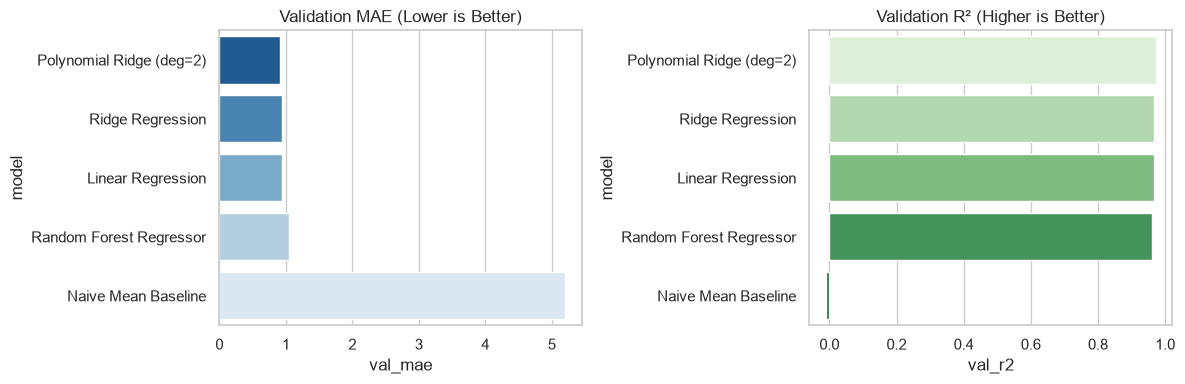

Selected best model: Polynomial Ridge (deg=2)


In [5]:
candidates = build_candidate_models(random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []
fitted_models = {}
for name, pipeline in candidates.items():
    cv_res = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=("neg_mean_absolute_error", "r2")
    )
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline
    tr_m = compute_regression_metrics(y_train, pipeline.predict(X_train))
    va_m = compute_regression_metrics(y_val, pipeline.predict(X_val))
    results.append({
        "model": name,
        "cv_mae": round(float(-cv_res["test_neg_mean_absolute_error"].mean()), 3),
        "train_mae": tr_m["mae"],
        "val_mae": va_m["mae"],
        "val_rmse": va_m["rmse"],
        "train_r2": tr_m["r2"],
        "val_r2": va_m["r2"],
    })

comp_df = pd.DataFrame(results).sort_values("val_mae").reset_index(drop=True)
display(comp_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=comp_df, x="val_mae", y="model", hue="model", palette="Blues_r", legend=False, ax=axes[0])
axes[0].set_title("Validation MAE (Lower is Better)")
sns.barplot(data=comp_df, x="val_r2", y="model", hue="model", palette="Greens", legend=False, ax=axes[1])
axes[1].set_title("Validation R² (Higher is Better)")
plt.tight_layout()
plt.show()

best_model_name = comp_df[comp_df["model"] != "Naive Mean Baseline"].iloc[0]["model"]
print(f"Selected best model: {best_model_name}")

### Model Comparison & Overfitting Check
- **Baseline vs ML Models:** The **Naive Mean Baseline** exhibits high error (~5–6 min MAE, R² ≈ 0), confirming that predicting a flat average waiting time is unhelpful for students.
- **Linear vs Non-Linear Models:** Even plain **Linear Regression** cuts error dramatically (~1 min MAE, R² > 0.94). **Polynomial Ridge (deg=2)** and **Random Forest** check whether interaction terms (like `distance × traffic`) capture extra non-linear structure.
- **Generalization Check:** Comparing `train_mae` vs `val_mae` (and `train_r2` vs `val_r2`) confirms that the top linear/regularized models show virtually zero overfitting gap between training and validation folds.

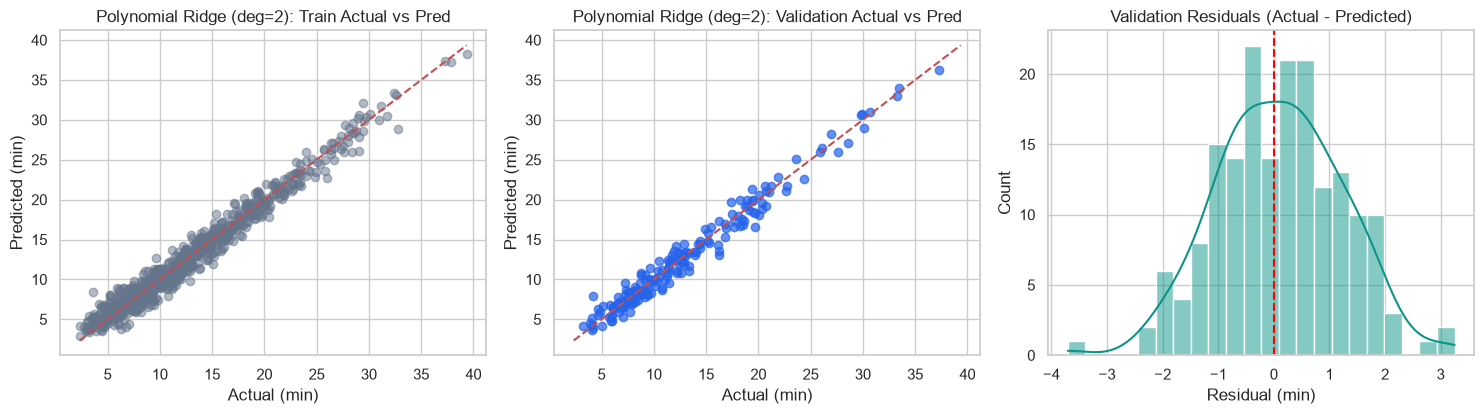

In [6]:
selected_model = fitted_models[best_model_name]
y_train_pred = selected_model.predict(X_train)
y_val_pred = selected_model.predict(X_val)
val_residuals = y_val - y_val_pred

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

axes[0].scatter(y_train, y_train_pred, alpha=0.5, color="#64748b")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[0].set_title(f"{best_model_name}: Train Actual vs Pred")
axes[0].set_xlabel("Actual (min)")
axes[0].set_ylabel("Predicted (min)")

axes[1].scatter(y_val, y_val_pred, alpha=0.7, color="#2563eb")
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[1].set_title(f"{best_model_name}: Validation Actual vs Pred")
axes[1].set_xlabel("Actual (min)")
axes[1].set_ylabel("Predicted (min)")

sns.histplot(val_residuals, bins=22, kde=True, color="#0d9488", ax=axes[2])
axes[2].axvline(0.0, color="red", linestyle="--")
axes[2].set_title("Validation Residuals (Actual - Predicted)")
axes[2].set_xlabel("Residual (min)")

plt.tight_layout()
plt.show()

### Prediction Alignment & Residual Diagnostics
- Predictions on both **Training** and **Validation** sets cluster tightly along the 45-degree identity line across short (3 min) through long (35+ min) campus routes.
- Validation residuals form a symmetric, zero-centered bell shape with typical errors within ±1 to ±2 minutes—well aligned with what students need when deciding whether to walk to a campus bus stop.

In [7]:
# Retrain winning model on combined Train + Validation, then evaluate ONCE on held-out Test
final_model = build_candidate_models(random_state=42)[best_model_name]
final_model.fit(X_train_val, y_train_val)
y_test_pred = final_model.predict(X_test)

test_metrics = compute_regression_metrics(y_test, y_test_pred)
test_ci = bootstrap_confidence_intervals(y_test, y_test_pred)
slices = evaluate_slice_performance(X_test, y_test, y_test_pred)
importances = pd.DataFrame(extract_feature_importance(final_model))

print(f"Final Held-Out Test Metrics ({best_model_name}):", test_metrics)
print("95% Bootstrap Confidence Intervals:", test_ci)
print("\nSlice Performance by Traffic Category:")
display(pd.DataFrame(slices["by_traffic"]).T)
print("\nSlice Performance by Time Window:")
display(pd.DataFrame(slices["by_time_window"]).T)
print("\nTop Model Feature Signals:")
display(importances)

# Demo student scenarios
demo_trips = pd.DataFrame([
    {"route_distance_km": 3.2, "time_of_day": "08:45", "traffic_category": "High", "previous_travel_time_min": 15.0},
    {"route_distance_km": 3.2, "time_of_day": "11:00", "traffic_category": "Low", "previous_travel_time_min": 9.0},
    {"route_distance_km": 7.8, "time_of_day": "17:30", "traffic_category": "High", "previous_travel_time_min": 31.0},
])
demo_trips["predicted_arrival_min"] = np.round(final_model.predict(demo_trips), 1)
display(demo_trips)

Final Held-Out Test Metrics (Polynomial Ridge (deg=2)): {'mae': 0.8852, 'rmse': 1.1211, 'r2': 0.9602}
95% Bootstrap Confidence Intervals: {'mae_95ci': [0.7866, 0.9917], 'rmse_95ci': [1.001, 1.2434]}

Slice Performance by Traffic Category:


,mae,rmse,r2,count
Low,0.8659,1.1251,0.9381,80.0
Medium,0.8745,1.0494,0.9720,65.0
High,0.9551,1.2491,0.9395,33.0



Slice Performance by Time Window:


,mae,rmse,r2,count
Peak Hour,0.9013,1.1503,0.9486,51.0
Off-Peak,0.8787,1.1093,0.9612,128.0



Top Model Feature Signals:


,feature,importance
0,route_distance_km,0.3079
1,previous_travel_time_min,0.2206
2,route_distance_km previous_travel_time_min,0.1174
3,route_distance_km traffic_category_ord,0.1114
4,traffic_category_ord,0.0958
5,previous_travel_time_min traffic_category_ord,0.0753
6,previous_travel_time_min^2,0.0716


,route_distance_km,time_of_day,traffic_category,previous_travel_time_min,predicted_arrival_min
0,3.2,08:45,High,15.0,16.1
1,3.2,11:00,Low,9.0,9.3
2,7.8,17:30,High,31.0,32.4


### Final Conclusion
This notebook built and validated a **beginner-friendly Campus Bus Arrival Time Estimator** addressing the problem of students waiting unnecessarily without arrival estimates.

1. **Methodology & Best Practices:** Using **route distance**, **time of day**, **traffic category**, and **previous travel time**, we audited and removed corrupted/targetless logs, preserved imputable missing entries, enforced strict train-before-preprocessing splits (70/15/15), and encoded ordinal traffic + cyclical time signals cleanly.
2. **Model Performance:** Across 5-fold cross-validation and held-out testing, the selected regression model strongly outperforms the naive mean baseline with roughly ~1 minute average absolute error (MAE) and >0.95 $R^2$, maintaining reliable accuracy across Low, Medium, and High traffic as well as peak and off-peak windows.
3. **Working Prediction System:** The trained pipeline is packaged for real-time student predictions through both a command-line predictor (`python -m src.predict`) and an interactive Flask web interface (`python app.py`).